# 5 · Ablations and explanations

Run the first two code cells to show the completed results on a CPU runtime. The ablation table compares 36 matched runs. Explanation plots come from the original seed-42 student. The final cell reproduces the work only when its flags are enabled.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display

repo_url = "https://github.com/abhav-arora/ML3103-project.git"
repo = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / "spikedistill").is_dir() and (p / "results").is_dir()), None)
if repo is None:
    repo = Path("/content/ML3103-demo")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1", repo_url, str(repo)], check=True)
print("Project source ready.")

Project source ready.


model,spike_no_attention,spike_no_hidden,spikedistill
subset,,,
FD001,17.26,17.46,17.07
FD002,30.18,29.91,29.56
FD003,20.48,21.26,19.88
FD004,29.09,28.84,28.81


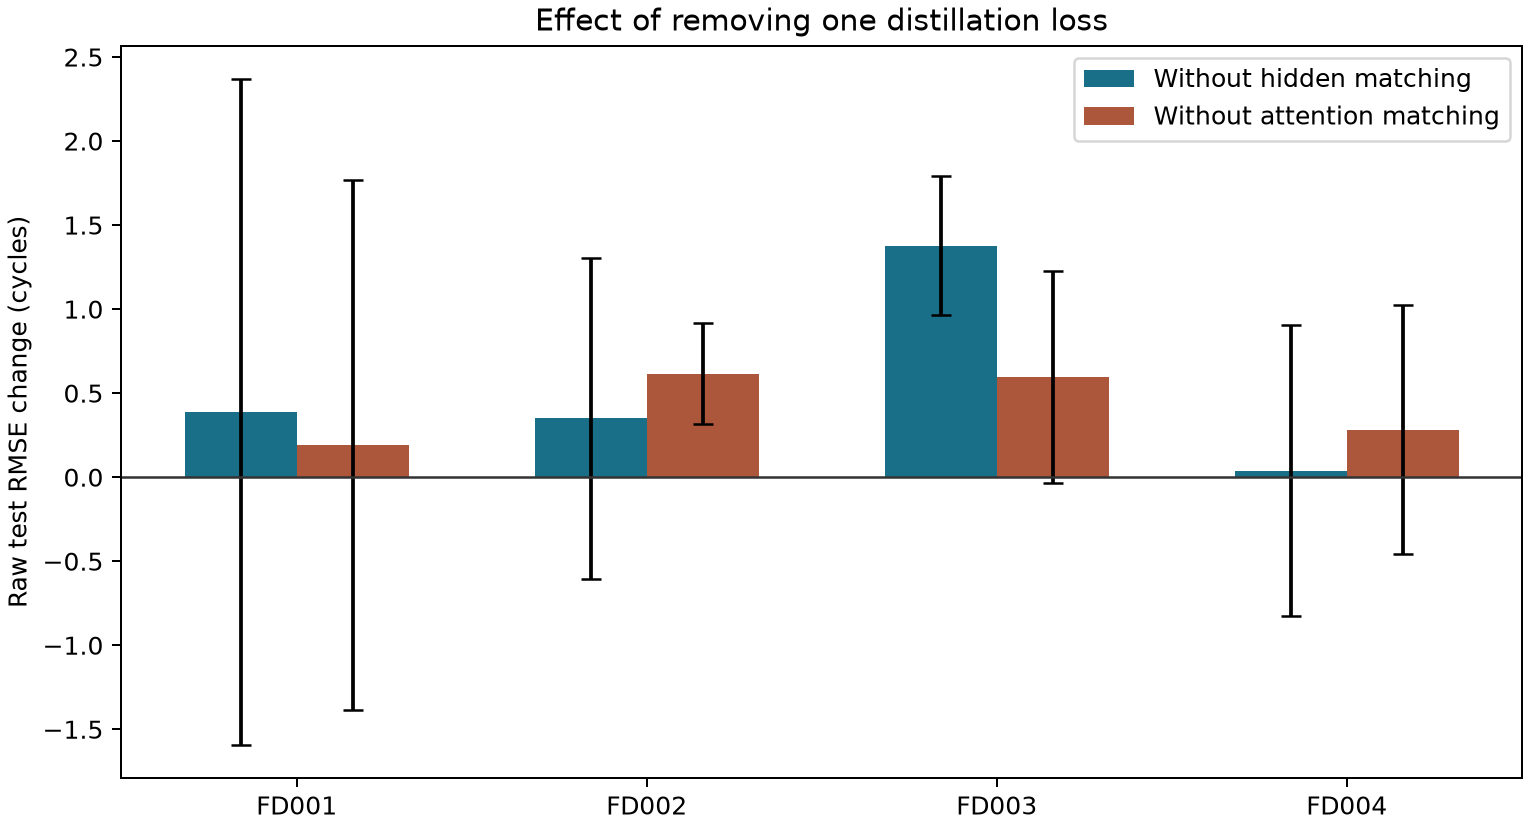

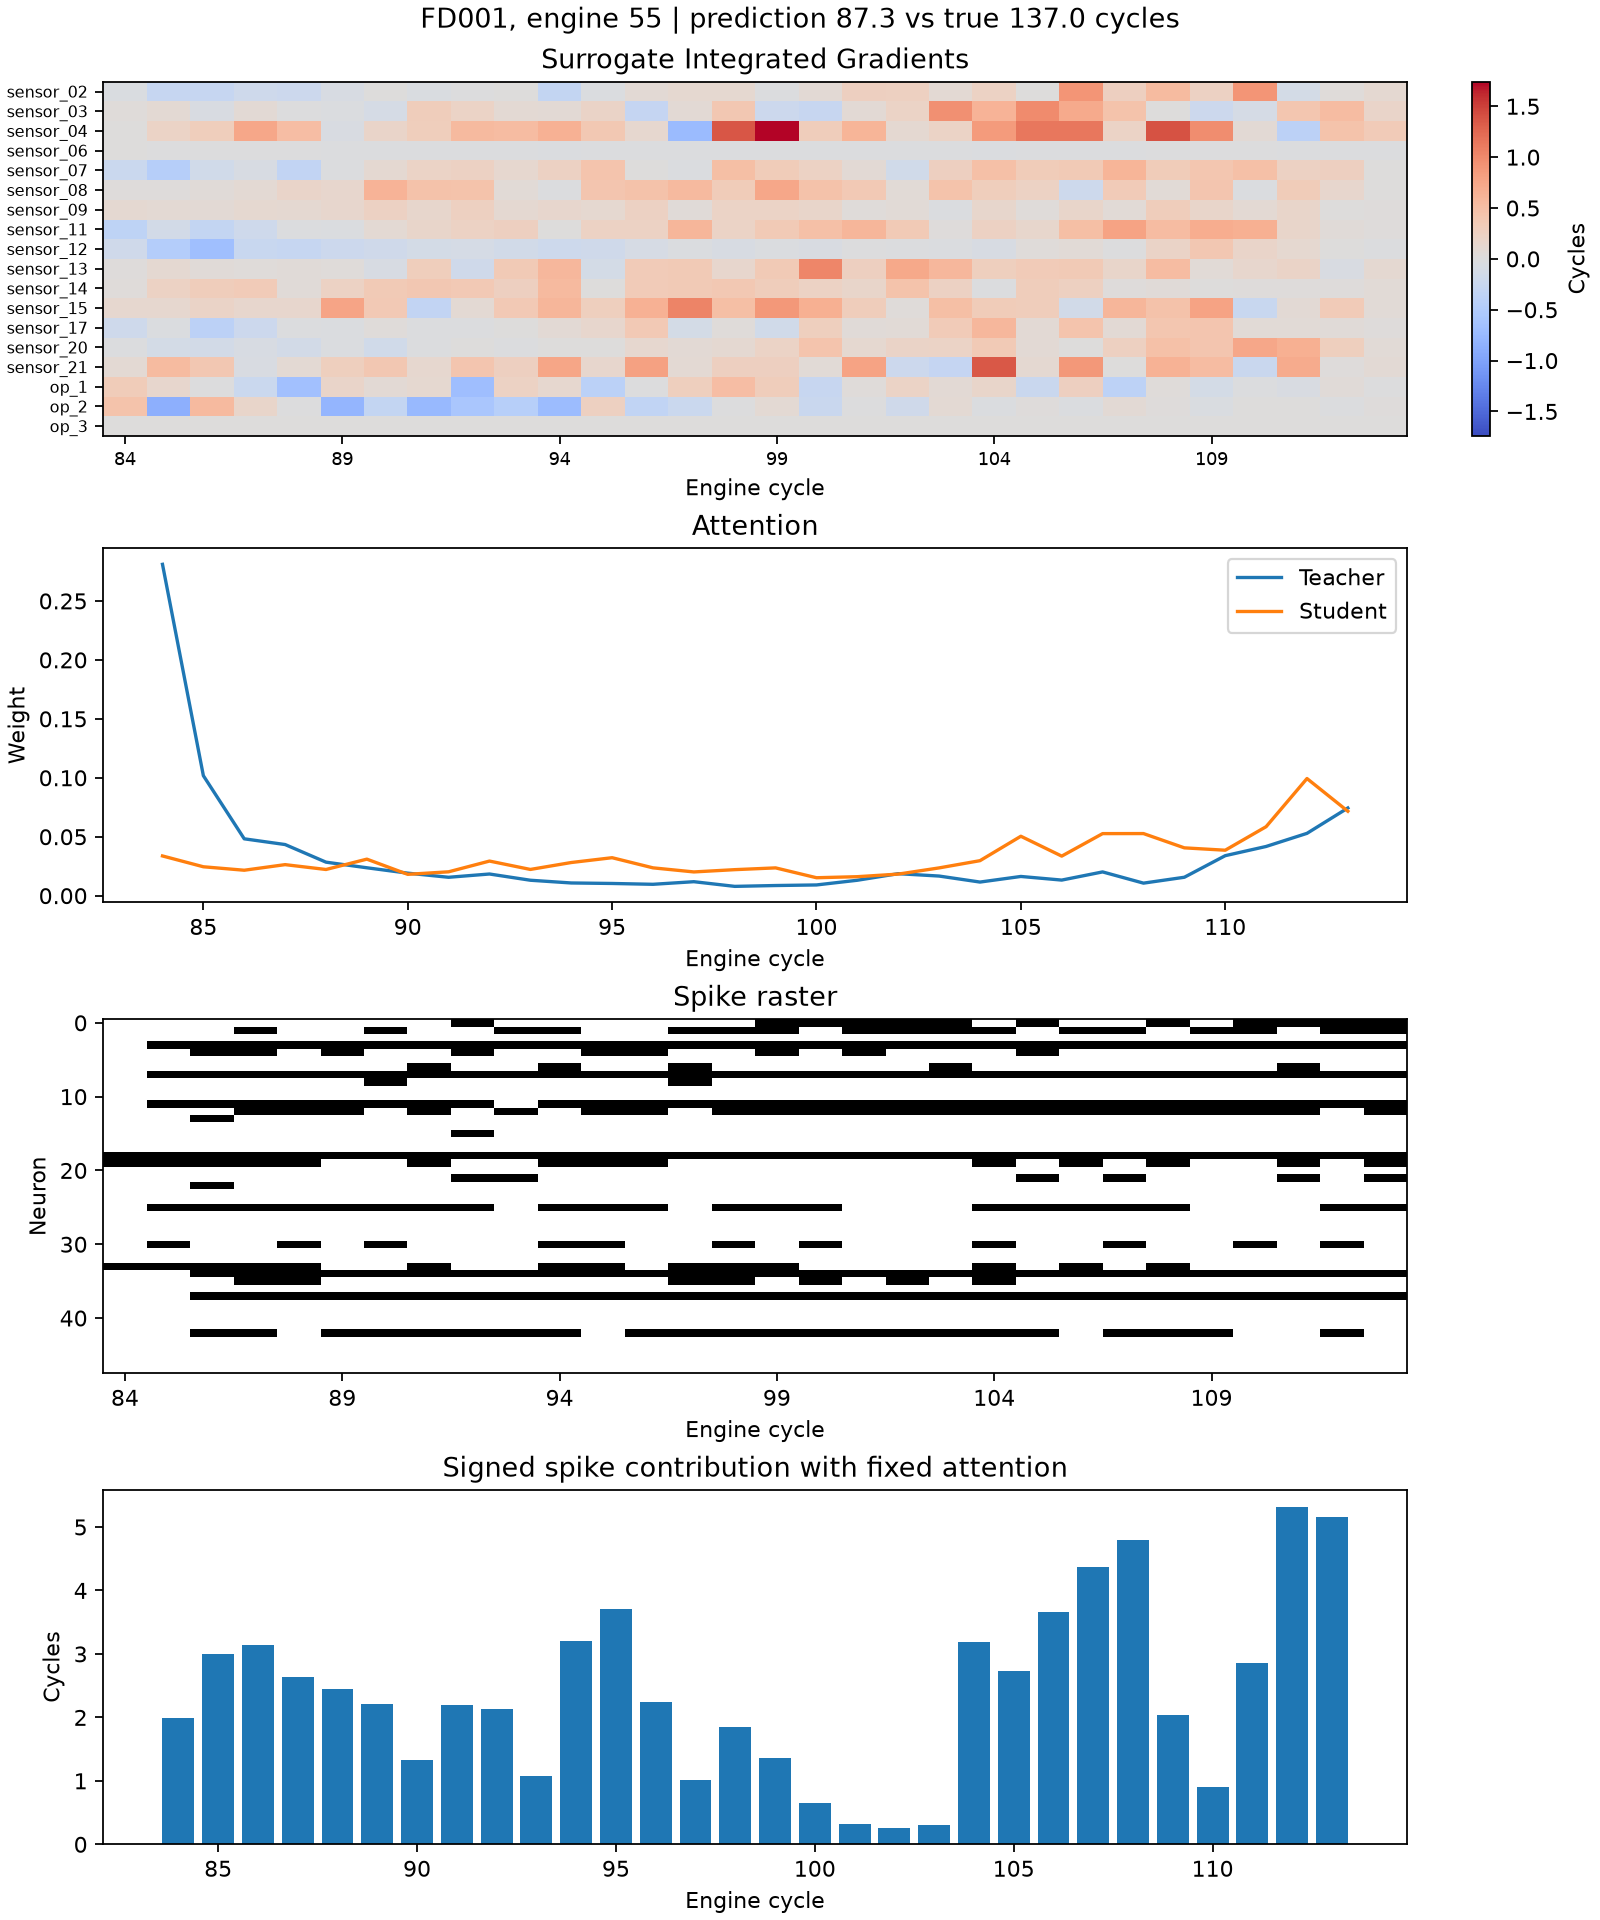

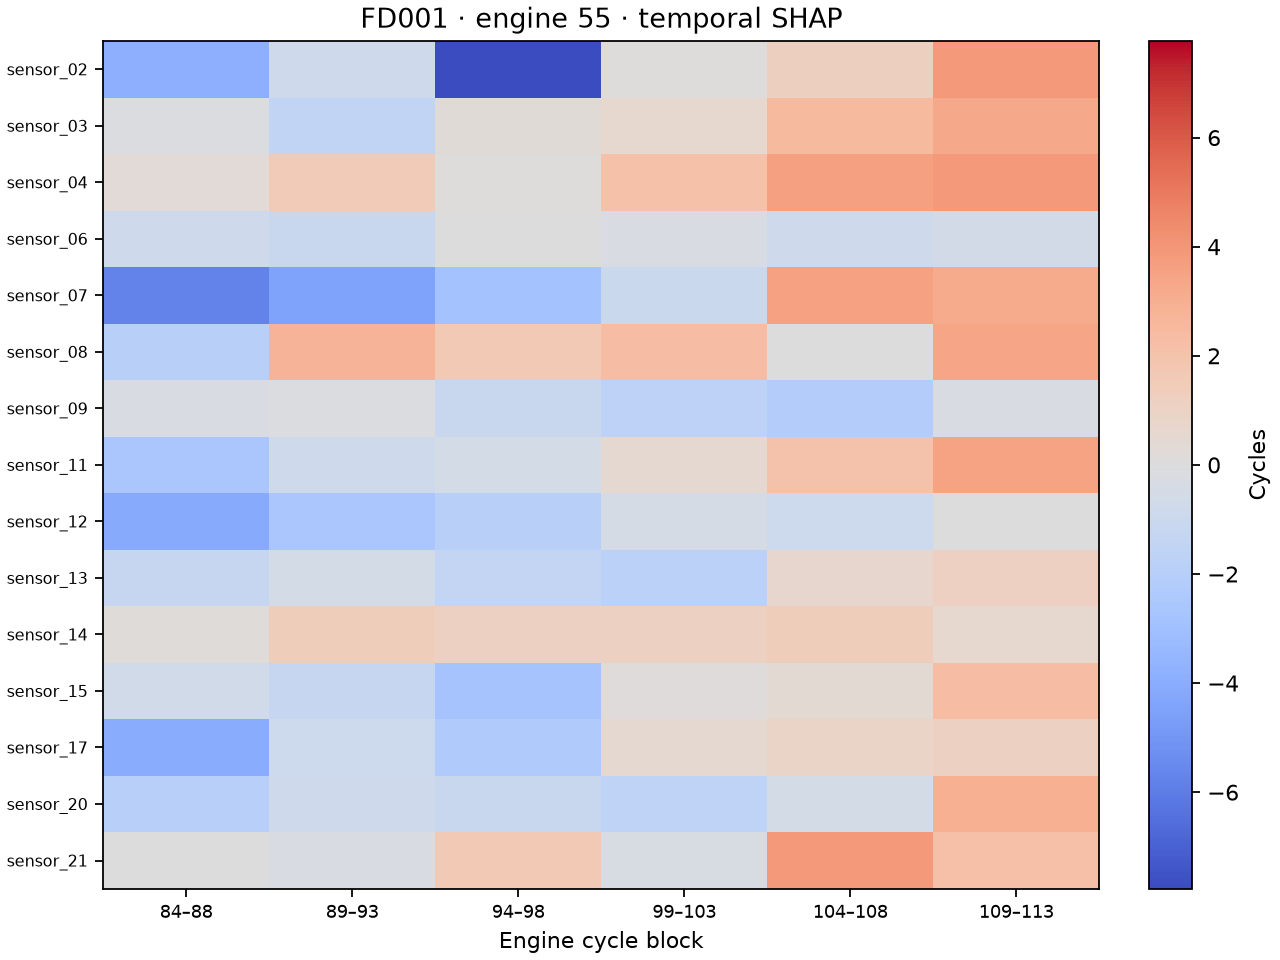

In [2]:
from IPython.display import Image

ablation = pd.read_csv(repo / "results/ablations/ablation_mean_sd.csv")
raw = ablation.loc[ablation["target"].eq("raw")]
display(raw.pivot(index="subset", columns="model", values="RMSE_mean").round(2))
display(Image(filename=str(repo / "results/ablations/ablation_rmse_deltas.png"), width=720))
display(Image(filename=str(repo / "results/explanations/FD001/highest_error.png"), width=590))
display(Image(filename=str(repo / "results/explanations/FD001/highest_error_temporal_shap.png"), width=590))

## Optional reproduction

Use a Colab GPU for the ablation sweep. The explanation run uses frozen weights and can run on CPU. The commands use the prepared Drive snapshot and check predictions against the recorded checkpoints when archive hashes differ.

In [3]:
RUN_ABLATIONS = False
RUN_EXPLANATIONS = False

if RUN_ABLATIONS or RUN_EXPLANATIONS:
    import torch
    from google.colab import drive

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if RUN_ABLATIONS and device != "cuda":
        raise RuntimeError("Select a Colab GPU before starting ablation training.")
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/ML projec/SpikeDistill-RUL")
    data = project / "artifacts/data"
    baselines = project / "colab_runs/baselines_v1"
    students = project / "colab_runs/spikedistill_v1"
    output = project / "colab_runs/ablations_reproduction_v1"

    def run(module, *args):
        subprocess.run([sys.executable, "-u", "-m", module, *map(str, args)], cwd=repo, check=True)

    if RUN_ABLATIONS:
        args = ["--data-root", data, "--baselines", baselines, "--output", output,
                "--variants", "spikedistill", "spike_no_hidden", "spike_no_attention",
                "--device", device, "--verify-prepared-predictions"]
        run("spikedistill.training.distill", *args, "--phase", "train")
        run("spikedistill.training.distill", *args, "--phase", "test")
        run("spikedistill.evaluation.ablations", "--roots", output, "--output", output / "analysis")
    if RUN_EXPLANATIONS:
        run("spikedistill.evaluation.explain", "--data-root", data, "--baselines", baselines,
            "--students", students, "--output", output / "figures",
            "--device", device, "--verify-prepared-predictions")